In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

from src.har.data import load
d = load()
print(d.features.shape)

(10299, 561)


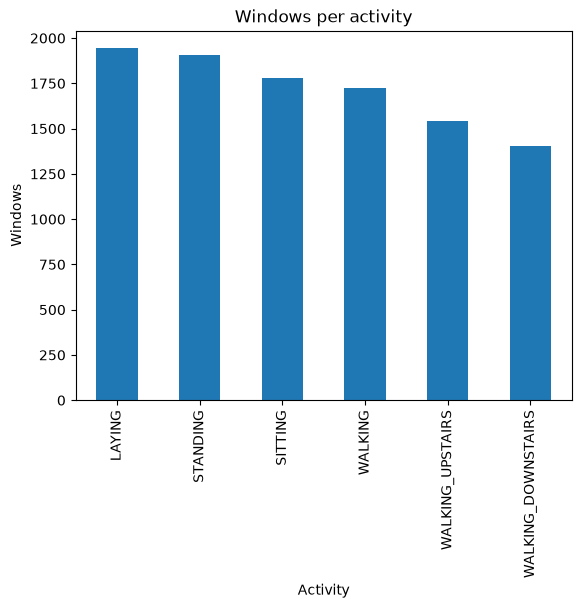

In [2]:
# Windows per activity - Are the counts for each relatively balanced?
lookup = {i: name for i, name in enumerate(d.activity_names)}
labels = pd.Series(d.y).map(lookup)
counts = labels.value_counts()
counts.plot.bar(
    xlabel="Activity", ylabel="Windows", title="Windows per activity")

plt.savefig("../figures/windows_per_activity.png", dpi=150, bbox_inches="tight")

Counts are relatively balanced for the activity IDs here, each activity has roughly 1,400–1,950 windows, so accuracy won’t be badly misleading

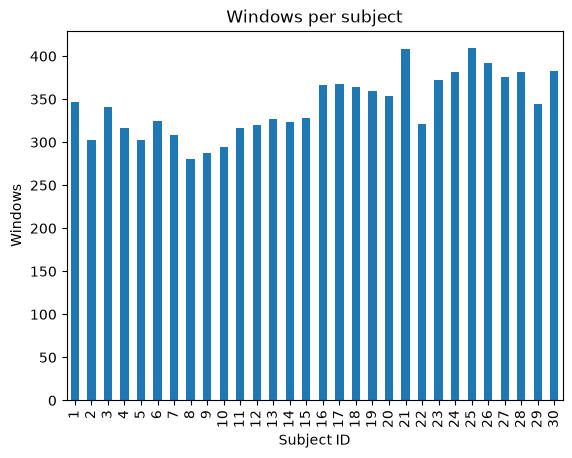

In [3]:
# Windows per subject - Are the counts for each relatively balanced?
pd.Series(d.subject).value_counts().sort_index().plot.bar(
    xlabel="Subject ID", ylabel="Windows", title="Windows per subject")

plt.savefig("../figures/windows_per_subject.png", dpi=150, bbox_inches="tight")

The windows for each individual are pretty balanced >275 for everyone. More than enough to work with and equal windows per person means no single person dominates training.

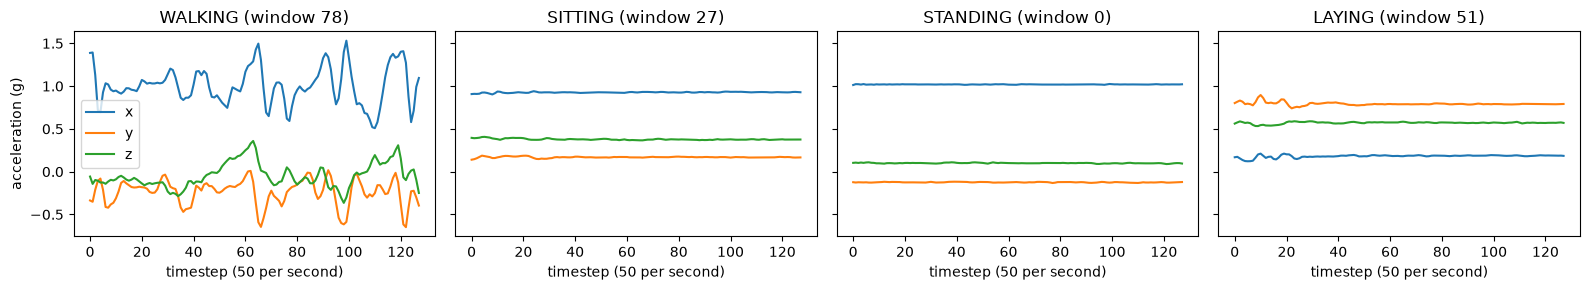

In [4]:
# One raw window per activity: pick one index for each of walking, sitting, standing and laying, and plot d.raw[i, 6:9].T. That’s total_acc x/y/z over the 128 timesteps.
import numpy as np

to_plot = ["WALKING", "SITTING", "STANDING", "LAYING"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)

for ax, name in zip(axes, to_plot):
    label = d.activity_names.index(name)   # "SITTING" -> 3
    i = np.flatnonzero(d.y == label)[0]    # first window with that label
    ax.plot(d.raw[i, 6:9].T)               # total_acc x, y, z over 128 timesteps
    ax.set_title(f"{name} (window {i})")
    ax.set_xlabel("timestep (50 per second)")

axes[0].set_ylabel("acceleration (g)")
axes[0].legend(["x", "y", "z"])
plt.tight_layout()
plt.savefig("../figures/raw_signals_per_activity.png", dpi=150, bbox_inches="tight")

Sitting and standing don't differ too much in terms of how the points over a time period move (acceleration is constant). Where they do differ, is that in sitting, acceleration g the y and z positions is higher than that of standing. This is likely due to the tilt of the smartphone used for measurement. The accelerometer always feels 1 g in total. Its axes are fixed to the phone, so when you sit, your hips rotate, the phone tilts, and that 1 g is shared differently across x, y and z. The direction of gravity relative to the phone changes, not its strength.